In [4]:
import pandas as pd
import numpy as np

In [5]:
df = pd.read_csv("data/final.csv")

In [6]:
cols = [
    "excess_ret",   # R_mt - R_ft
    "VRP",          # IV - RV
    "IV",
    "RV",
    "log_PE",
    "log_PD",
    "DFSP",
    "TMSP",
    "RREL",
    "CAY"
]

In [29]:
import numpy as np
import pandas as pd

df_sub = df[cols].dropna()

mean_factor = 12
std_factor = np.sqrt(12)

annualize_cols = ["excess_ret", "VRP", "IV", "RV"]

def ar1(x):
    return x.autocorr(lag=1)

summary = pd.DataFrame(
    index=["Mean", "Std. dev.", "Skewness", "Kurtosis", "AR(1)"],
    columns=df_sub.columns,
    dtype=float
)

# Mean
summary.loc["Mean"] = df_sub.mean()
summary.loc["Mean", annualize_cols] *= mean_factor

# Std
summary.loc["Std. dev."] = df_sub.std()
summary.loc["Std. dev.", annualize_cols] *= std_factor

# Rest unverändert
summary.loc["Skewness"] = df_sub.skew()
summary.loc["Kurtosis"] = df_sub.kurtosis()
summary.loc["AR(1)"] = df_sub.apply(ar1)

summary = summary.round(2)
summary

,excess_ret,VRP,IV,RV,log_PE,log_PD,DFSP,TMSP,RREL,CAY
Mean,0.09,0.05,0.60,0.55,3.14,3.90,1.11,1.86,-0.13,-0.02
Std. dev.,0.16,0.12,0.21,0.12,0.43,0.14,0.50,0.97,0.50,0.02
Skewness,-0.66,3.80,3.70,3.56,2.26,-1.60,2.60,-0.17,-1.88,0.04
Kurtosis,1.61,18.88,15.89,17.29,5.72,5.13,7.79,-0.65,4.25,-0.56
AR(1),0.08,0.76,0.76,0.59,0.98,0.95,0.95,0.98,0.96,0.95


In [32]:
latex_table = summary.to_latex(
    float_format="%.2f",
    caption="Summary Statistics",
    label="tab:summary",
    column_format="l" + "c"*len(summary.columns)
)

print(latex_table)

\begin{table}
\caption{Summary Statistics}
\label{tab:summary}
\begin{tabular}{lcccccccccc}
\toprule
 & excess_ret & VRP & IV & RV & log_PE & log_PD & DFSP & TMSP & RREL & CAY \\
\midrule
Mean & 0.09 & 0.05 & 0.60 & 0.55 & 3.14 & 3.90 & 1.11 & 1.86 & -0.13 & -0.02 \\
Std. dev. & 0.16 & 0.12 & 0.21 & 0.12 & 0.43 & 0.14 & 0.50 & 0.97 & 0.50 & 0.02 \\
Skewness & -0.66 & 3.80 & 3.70 & 3.56 & 2.26 & -1.60 & 2.60 & -0.17 & -1.88 & 0.04 \\
Kurtosis & 1.61 & 18.88 & 15.89 & 17.29 & 5.72 & 5.13 & 7.79 & -0.65 & 4.25 & -0.56 \\
AR(1) & 0.08 & 0.76 & 0.76 & 0.59 & 0.98 & 0.95 & 0.95 & 0.98 & 0.96 & 0.95 \\
\bottomrule
\end{tabular}
\end{table}



In [8]:
corr = df_sub.corr().round(2)

# untere Dreiecksmatrix (wie im Paper)
corr_lower = corr.copy()
corr_lower.values[np.triu_indices_from(corr_lower, k=1)] = np.nan

corr_lower

,excess_ret,VRP,IV,RV,log_PE,log_PD,DFSP,TMSP,RREL,CAY
excess_ret,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
VRP,-0.15,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IV,-0.37,0.91,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RV,-0.53,0.66,0.91,1.00,NaN,NaN,NaN,NaN,NaN,NaN
log_PE,0.07,0.44,0.38,0.25,1.00,NaN,NaN,NaN,NaN,NaN
log_PD,0.19,-0.59,-0.63,-0.56,-0.52,1.00,NaN,NaN,NaN,NaN
DFSP,-0.13,0.75,0.76,0.63,0.57,-0.85,1.00,NaN,NaN,NaN
TMSP,-0.04,0.16,0.16,0.14,0.07,-0.33,0.23,1.00,NaN,NaN
RREL,0.12,-0.55,-0.58,-0.51,-0.33,0.37,-0.54,-0.07,1.00,NaN
CAY,-0.15,0.27,0.32,0.31,-0.06,-0.59,0.48,0.68,-0.27,1.0


<Axes: >

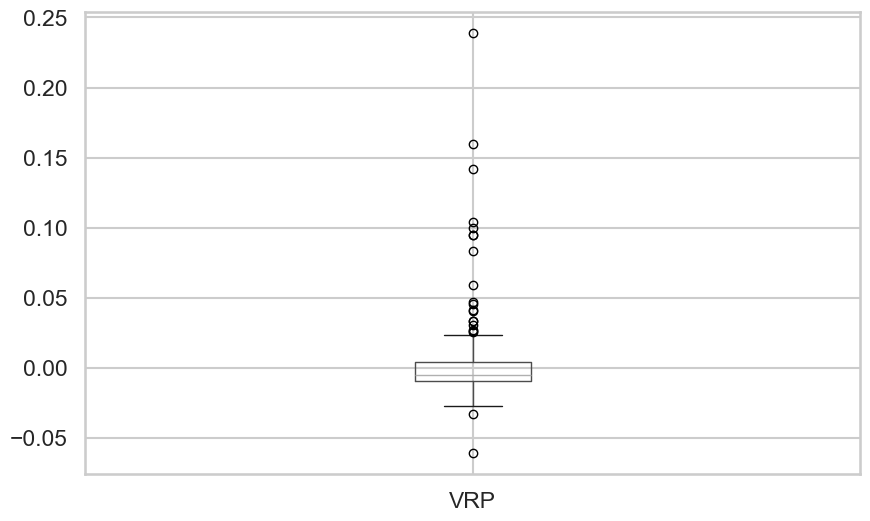

In [9]:
df_sub.boxplot(column="VRP")

In [10]:
!pip install seaborn

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Consistent plotting style for paper-ready figures
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

# Keep only numeric columns for advanced EDA
df_num = df.select_dtypes(include=[np.number]).copy()

time_col = "Date" if "Date" in df.columns else None
if time_col is not None:
    df[time_col] = pd.to_datetime(df[time_col], errors="coerce")

,Mean,Std,Skew,Excess Kurtosis,Jarque-Bera,JB p-value,VaR 5%,CVaR 5%
Variable,,,,,,,,
IV,0.0504,0.0613,3.7046,15.8853,1918.3782,0.0,0.0132,0.0111
RV,0.0460,0.0336,3.5567,17.2915,2179.8923,0.0,0.0197,0.0176
VIX3M,21.7230,8.3166,1.8035,3.7161,168.6665,0.0,13.3078,12.8719
VRP,0.0045,0.0338,3.7975,18.8780,2581.9993,0.0,-0.0162,-0.0276
excess_ret,0.0076,0.0460,-0.6645,1.6143,26.9191,0.0,-0.0751,-0.1079
log_ret,0.0072,0.0464,-0.9032,2.1634,49.2815,0.0,-0.0780,-0.1138


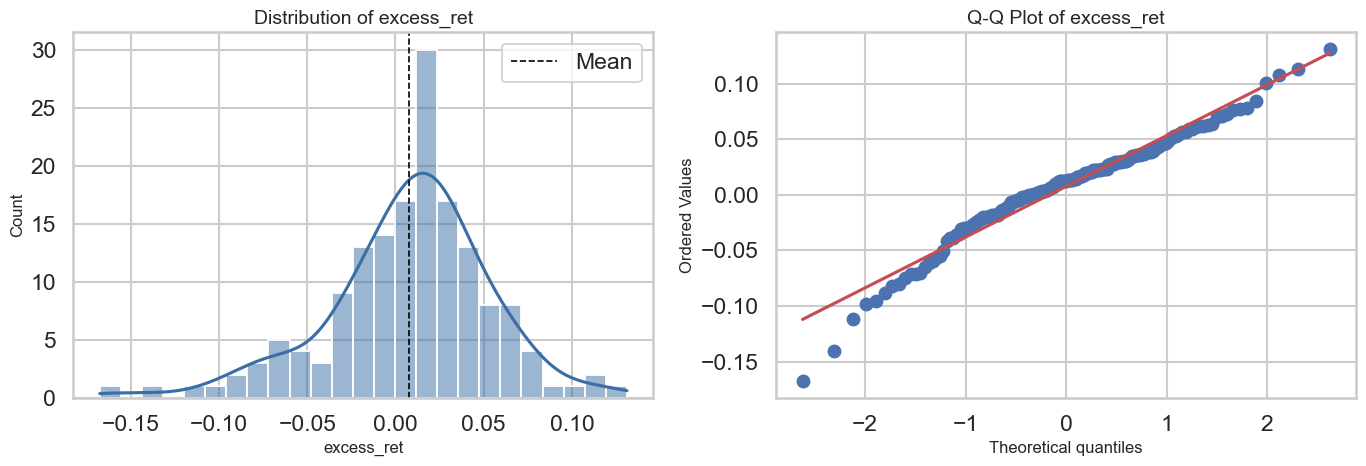

In [12]:
# 1) Distribution diagnostics: normality + tail risk
focus_cols = [c for c in ["excess_ret", "VRP", "IV", "RV", "VIX3M", "log_ret"] if c in df_num.columns]

records = []
for c in focus_cols:
    x = df_num[c].dropna()
    if len(x) < 10:
        continue
    jb_stat, jb_p = stats.jarque_bera(x)
    records.append({
        "Variable": c,
        "Mean": x.mean(),
        "Std": x.std(),
        "Skew": stats.skew(x, bias=False),
        "Excess Kurtosis": stats.kurtosis(x, fisher=True, bias=False),
        "Jarque-Bera": jb_stat,
        "JB p-value": jb_p,
        "VaR 5%": x.quantile(0.05),
        "CVaR 5%": x[x <= x.quantile(0.05)].mean(),
    })

dist_table = pd.DataFrame(records).set_index("Variable").sort_index()
display(dist_table.round(4))

# Visual diagnostics for a key variable (if available)
key_var = "excess_ret" if "excess_ret" in focus_cols else focus_cols[0]
x = df_num[key_var].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(x, kde=True, bins=25, color="#3A6EA5", ax=axes[0])
axes[0].set_title(f"Distribution of {key_var}")
axes[0].axvline(x.mean(), color="black", linestyle="--", linewidth=1.2, label="Mean")
axes[0].legend()

stats.probplot(x, dist="norm", plot=axes[1])
axes[1].set_title(f"Q-Q Plot of {key_var}")

plt.tight_layout()
plt.show()

VIX3M                        excess_ret                        \
               mean     std   median count       mean     std  median count   
VIX_regime                                                                    
Low         14.9648  1.1451  15.2455    53     0.0163  0.0206  0.0175    53   
Medium      19.2906  1.4705  19.2304    53     0.0082  0.0366  0.0122    53   
High        30.9136  8.2470  28.3314    53    -0.0017  0.0671 -0.0022    53   

               VRP                        
              mean     std  median count  
VIX_regime                                
Low        -0.0082  0.0032 -0.0080    53  
Medium     -0.0089  0.0098 -0.0077    53  
High        0.0305  0.0483  0.0148    53

,Test,Statistic,p-value
0,ANOVA (means),2.0641,0.1304
1,Kruskal-Wallis (distribution),2.8137,0.2449


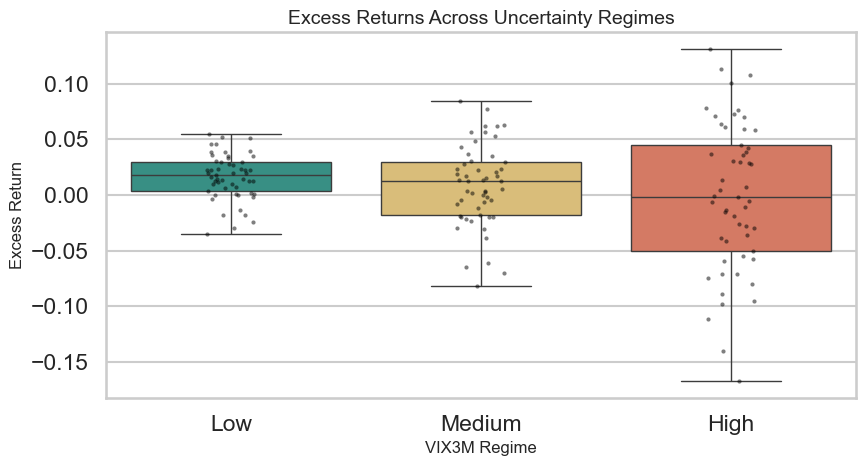

In [18]:
# 3) Regime analysis using VIX3M quantiles (low/medium/high uncertainty)
if "VIX3M" in df_num.columns and "excess_ret" in df_num.columns:
    reg_df = df_num[["VIX3M", "excess_ret"] + (["VRP"] if "VRP" in df_num.columns else [])].dropna().copy()
    reg_df["VIX_regime"] = pd.qcut(reg_df["VIX3M"], q=3, labels=["Low", "Medium", "High"])

    # Group summary
    regime_summary = reg_df.groupby("VIX_regime", observed=False).agg(["mean", "std", "median", "count"])
    display(regime_summary.round(4))

    # Non-parametric and parametric tests for excess returns across regimes
    groups = [g["excess_ret"].values for _, g in reg_df.groupby("VIX_regime", observed=False)]
    f_stat, f_p = stats.f_oneway(*groups)
    h_stat, h_p = stats.kruskal(*groups)

    test_results = pd.DataFrame({
        "Test": ["ANOVA (means)", "Kruskal-Wallis (distribution)"],
        "Statistic": [f_stat, h_stat],
        "p-value": [f_p, h_p]
    })
    display(test_results.round(4))

    # Visual comparison
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.boxplot(
        data=reg_df,
        x="VIX_regime",
        y="excess_ret",
        hue="VIX_regime",
        palette=["#2A9D8F", "#E9C46A", "#E76F51"],
        legend=False,
        ax=ax
    )
    sns.stripplot(data=reg_df, x="VIX_regime", y="excess_ret", color="black", size=3, alpha=0.5, ax=ax)
    ax.set_title("Excess Returns Across Uncertainty Regimes")
    ax.set_xlabel("VIX3M Regime")
    ax.set_ylabel("Excess Return")
    plt.tight_layout()
    plt.show()
else:
    print("Regime analysis skipped: requires VIX3M and excess_ret.")

In [21]:
# Add regime labels from reg_df to df (aligned by index)
df["VIX_Regime"] = reg_df["VIX_regime"]

# Optional check
df[["VIX3M", "VIX_Regime"]].head()

,VIX3M,VIX_Regime
0,25.394500,High
1,26.888000,High
2,22.488636,Medium
3,20.617619,Medium
4,23.129524,High


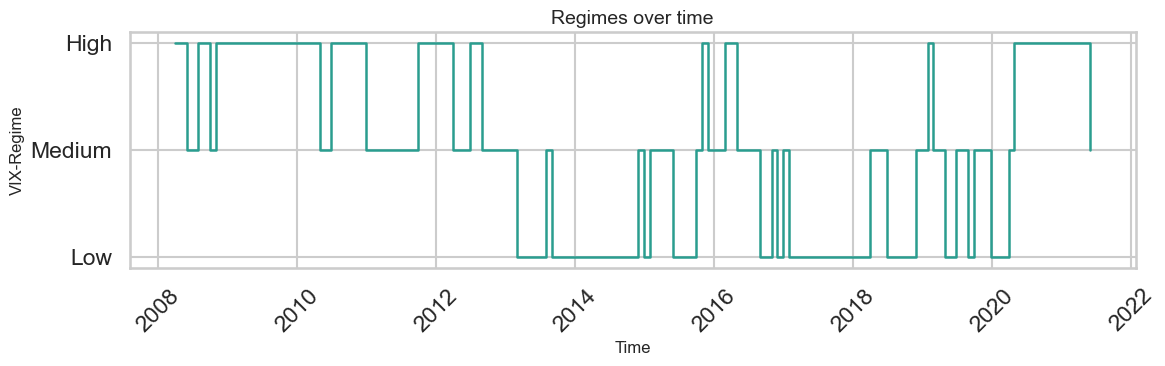

In [26]:
# Zeitachse aus dem Datumsfeld bauen (falls vorhanden)
date_col = "Unnamed: 0" if "Unnamed: 0" in df.columns else None
dates = pd.to_datetime(df.loc[reg_df.index, date_col], errors="coerce") if date_col else reg_df.index

# Regime in numerische Stufen umwandeln und über Zeit plotten
regime_order = ["Low", "Medium", "High"]
regime_num = reg_df["VIX_regime"].astype(str).map({k: i for i, k in enumerate(regime_order)})

fig, ax = plt.subplots(figsize=(12, 4))
ax.step(dates, regime_num, where="post", linewidth=1.8, color="#2A9D8F")
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(regime_order)
ax.set_xlabel("Time")
ax.set_ylabel("VIX-Regime")
ax.set_title("Regimes over time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
df = pd.get_dummies(df, columns=["VIX_Regime"], drop_first=True)

In [24]:
df

,Unnamed: 0,log_ret,monthly_return,IV,RV,VRP,log_PE,log_PD,CAY,BAA,...,GS10,TB3MS,DFSP,TMSP,RREL,excess_ret,cay_imputed,VIX3M,VIX_Regime_Medium,VIX_Regime_High
0,2008-03-31,-0.014079,-0.025783,0.065171,0.058995,0.006176,3.079178,3.875335,0.006081,6.82,...,3.74,2.12,1.29,1.62,-1.805000,-0.027531,0.006081,25.394500,False,True
1,2008-04-30,0.048108,-0.013980,0.073852,0.075129,-0.001277,3.082243,3.840204,0.009843,6.89,...,3.51,1.26,1.38,2.25,-2.358333,-0.015024,0.009843,26.888000,False,True
2,2008-05-31,0.013493,0.049283,0.046684,0.046326,0.000358,3.173155,3.875230,0.009843,6.97,...,3.68,1.29,1.42,2.39,-2.030000,0.048215,0.009843,22.488636,True,False
3,2008-06-30,-0.091226,0.013585,0.033596,0.037002,-0.003406,3.250590,3.894051,0.009843,6.93,...,3.88,1.73,1.36,2.15,-1.340000,0.012155,0.009843,20.617619,True,False
4,2008-07-31,-0.009495,-0.087189,0.049107,0.050400,-0.001293,3.262303,3.844112,-0.006757,7.07,...,4.10,1.86,1.39,2.24,-0.980833,-0.088725,-0.006757,23.129524,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,2021-01-31,-0.013283,0.027612,0.050212,0.031184,0.019028,3.670143,4.149581,-0.043572,3.16,...,0.93,0.09,0.90,0.84,-0.275000,0.027537,-0.043572,25.429091,False,True
155,2021-02-28,0.028761,-0.013195,0.063758,0.040120,0.023637,3.582525,4.179569,-0.043469,3.24,...,1.08,0.08,0.79,1.00,-0.165000,-0.013261,-0.043469,27.552632,False,True
156,2021-03-31,0.041269,0.029179,0.054342,0.037756,0.016587,3.503641,4.206646,-0.043030,3.42,...,1.26,0.04,0.72,1.22,-0.081667,0.029145,-0.043030,27.811579,False,True
157,2021-04-30,0.051760,0.042132,0.048388,0.050433,-0.002045,3.417831,4.217321,-0.042450,3.74,...,1.61,0.03,0.70,1.58,-0.070000,0.042107,-0.042450,25.341739,False,True


In [27]:
df.to_csv("data/final.csv")